# Treinamento e teste de diferentes modelos 

## Importando Dados

In [8]:
from pathlib import Path

import joblib

raiz = Path.cwd()
if not (raiz / "Modelos").is_dir():
    raiz = raiz.parent

dados = joblib.load(raiz / "Modelos" / "dados_ml.joblib")

X_treino = dados["X"]["treino"]
y_treino = dados["y"]["treino"]

X_validacao = dados["X"]["validacao"]
y_validacao = dados["y"]["validacao"]

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_validacao.shape, y_validacao.shape)

Treino: (41173, 159) (41173,)
Validação: (24667, 159) (24667,)


In [9]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino, y_treino)

previsoes = baseline.predict(X_validacao)
scores = baseline.predict_proba(X_validacao)[:, 1]

print(f"Accuracy: {accuracy_score(y_validacao, previsoes):.2%}")
print(f"Precision: {precision_score(y_validacao, previsoes, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao, previsoes, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao, previsoes, zero_division=0):.2%}")
print(f"Average Precision: {average_precision_score(y_validacao, scores):.4f}")

Accuracy: 89.89%
Precision: 0.00%
Recall: 0.00%
F1: 0.00%
Average Precision: 0.1011


# Treinamento 1: Regressão Logística

In [10]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)

modelo_logistico.fit(X_treino, y_treino)

print("Modelo treinado.")

Modelo treinado.


In [11]:
previsoes_log = modelo_logistico.predict(X_validacao)
scores_log = modelo_logistico.predict_proba(X_validacao)[:, 1]

print(f"Accuracy: {accuracy_score(y_validacao, previsoes_log):.2%}")
print(f"Precision: {precision_score(y_validacao, previsoes_log, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao, previsoes_log, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao, previsoes_log, zero_division=0):.2%}")
print(f"Average Precision: {average_precision_score(y_validacao, scores_log):.4f}")

Accuracy: 67.11%
Precision: 16.17%
Recall: 53.85%
F1: 24.87%
Average Precision: 0.1890


In [12]:
import pandas as pd

resultados_limites = []

for limite in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    alertas = (scores_log >= limite).astype(int)

    resultados_limites.append({
        "limite": limite,
        "precision_%": 100 * precision_score(y_validacao, alertas, zero_division=0),
        "recall_%": 100 * recall_score(y_validacao, alertas, zero_division=0),
        "f1_%": 100 * f1_score(y_validacao, alertas, zero_division=0),
        "pedidos_alertados": int(alertas.sum()),
        "falsos_alertas": int(((alertas == 1) & (y_validacao == 0)).sum())
    })

tabela_limites = pd.DataFrame(resultados_limites)
tabela_limites.round(2)

,limite,precision_%,recall_%,f1_%,pedidos_alertados,falsos_alertas
0,0.2,10.87,97.67,19.56,22411,19975
1,0.3,11.92,90.10,21.05,18857,16610
2,0.4,13.41,73.70,22.70,13702,11864
3,0.5,16.17,53.85,24.87,8305,6962
4,0.6,20.74,34.48,25.90,4146,3286
5,0.7,24.68,16.84,20.02,1702,1282
6,0.8,28.93,5.97,9.90,515,366


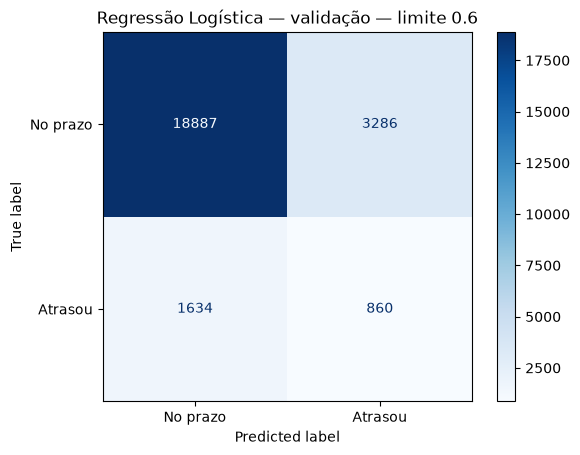

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

limite_provisorio = 0.6
previsoes_validacao = (scores_log >= limite_provisorio).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_validacao,
    previsoes_validacao,
    display_labels=["No prazo", "Atrasou"],
    cmap="Blues",
    values_format="d"
)

plt.title("Regressão Logística — validação — limite 0.6")
plt.show()

# Avaliação no teste — Regressão logística

In [14]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)

modelo_logistico.fit(
    dados["X"]["treino"],
    dados["y"]["treino"]
)

scores_log_teste = modelo_logistico.predict_proba(
    dados["X"]["teste"]
)[:, 1]

In [15]:
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

avaliacao_log_teste = pd.DataFrame({
    "atrasou": dados["y"]["teste"],
    "score": scores_log_teste
})

quantidade_log = int(len(avaliacao_log_teste) * 0.10)
indices_log = avaliacao_log_teste.nlargest(
    quantidade_log, "score"
).index

avaliacao_log_teste["prioridade"] = 0
avaliacao_log_teste.loc[indices_log, "prioridade"] = 1

real_log = avaliacao_log_teste["atrasou"]
alertas_log = avaliacao_log_teste["prioridade"]

print(f"Pedidos avaliados: {len(avaliacao_log_teste)}")
print(f"Pedidos na fila: {quantidade_log}")
print(f"Atrasos encontrados: {int(real_log[alertas_log == 1].sum())}")
print(f"Precision: {precision_score(real_log, alertas_log):.2%}")
print(f"Recall: {recall_score(real_log, alertas_log):.2%}")
print(f"F1: {f1_score(real_log, alertas_log):.2%}")
print(f"AP: {average_precision_score(real_log, scores_log_teste):.4f}")
print("Matriz de confusão:")
print(confusion_matrix(real_log, alertas_log, labels=[0, 1]))

Pedidos avaliados: 25550
Pedidos na fila: 2555
Atrasos encontrados: 276
Precision: 10.80%
Recall: 24.56%
F1: 15.00%
AP: 0.0885
Matriz de confusão:
[[22147  2279]
 [  848   276]]


# Treinamento 2: HistGradientBoosting (HGB)

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier

modelo_hgb = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    class_weight="balanced",
    early_stopping=False,
    random_state=42
)

modelo_hgb.fit(X_treino, y_treino)
print("HGB treinado.")

HGB treinado.


In [17]:
previsoes_hgb = modelo_hgb.predict(X_validacao)
scores_hgb = modelo_hgb.predict_proba(X_validacao)[:, 1]

print(f"Accuracy: {accuracy_score(y_validacao, previsoes_hgb):.2%}")
print(f"Precision: {precision_score(y_validacao, previsoes_hgb, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao, previsoes_hgb, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao, previsoes_hgb, zero_division=0):.2%}")
print(f"Average Precision: {average_precision_score(y_validacao, scores_hgb):.4f}")

Accuracy: 72.92%
Precision: 14.92%
Recall: 35.69%
F1: 21.04%
Average Precision: 0.1529


# Treinamento 3: Rede Neural (MLP)

In [18]:
import numpy as np
import torch
from torch import nn

# Tensores são o formato de dados utilizado pelo PyTorch.
X_treino_tensor = torch.tensor(np.asarray(X_treino), dtype=torch.float32)
y_treino_tensor = torch.tensor(np.asarray(y_treino), dtype=torch.float32)

X_validacao_tensor = torch.tensor(np.asarray(X_validacao), dtype=torch.float32)
y_validacao_tensor = torch.tensor(np.asarray(y_validacao), dtype=torch.float32)

print("PyTorch:", torch.__version__)
print("Treino:", X_treino_tensor.shape, y_treino_tensor.shape)
print("Validação:", X_validacao_tensor.shape, y_validacao_tensor.shape)

PyTorch: 2.15.0+cpu
Treino: torch.Size([41173, 159]) torch.Size([41173])
Validação: torch.Size([24667, 159]) torch.Size([24667])


Exemplos [no prazo, atraso]: [39408, 39408]
Época 001 | Perda treino: 0.5995 | Perda validação: 0.6295 | AP: 0.1973 | Atrasos na fila: 592 | Paciência: 0/1500
Época 002 | Perda treino: 0.5631 | Perda validação: 0.7092 | AP: 0.1595 | Atrasos na fila: 465 | Paciência: 1/1500
Época 003 | Perda treino: 0.5337 | Perda validação: 0.6953 | AP: 0.1420 | Atrasos na fila: 429 | Paciência: 2/1500
Época 004 | Perda treino: 0.5052 | Perda validação: 0.6936 | AP: 0.1353 | Atrasos na fila: 386 | Paciência: 3/1500
Época 005 | Perda treino: 0.4795 | Perda validação: 0.6939 | AP: 0.1317 | Atrasos na fila: 380 | Paciência: 4/1500
Época 006 | Perda treino: 0.4541 | Perda validação: 0.7193 | AP: 0.1273 | Atrasos na fila: 363 | Paciência: 5/1500
Época 007 | Perda treino: 0.4371 | Perda validação: 0.7380 | AP: 0.1267 | Atrasos na fila: 354 | Paciência: 6/1500
Época 008 | Perda treino: 0.4162 | Perda validação: 0.7021 | AP: 0.1258 | Atrasos na fila: 342 | Paciência: 7/1500
Época 009 | Perda treino: 0.4031 | P

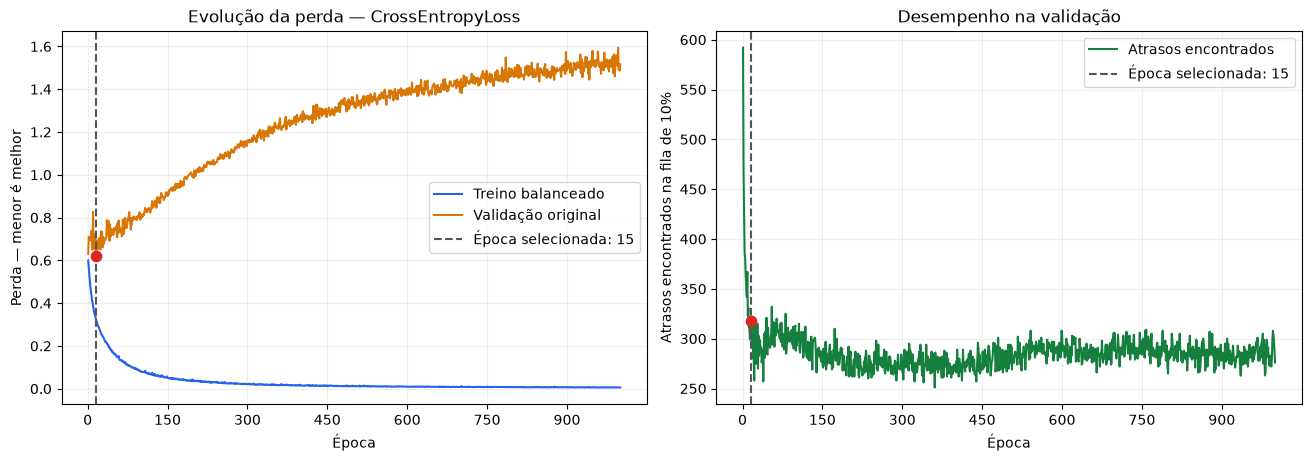

In [19]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from copy import deepcopy
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# ==================================================
# 1. Configurações
# ==================================================
SEMENTE_CE = 7
EPOCAS_CE = 1000
PACIENCIA_CE = 1500
MIN_DELTA_CE = 0.0001

torch.manual_seed(SEMENTE_CE)

# ==================================================
# 2. Dados já preparados pelo pré-processamento
# ==================================================
X_treino_ce = torch.tensor(
    np.asarray(X_treino), dtype=torch.float32
)
y_treino_ce = torch.tensor(
    np.asarray(y_treino).ravel(), dtype=torch.long
)

X_validacao_ce = torch.tensor(
    np.asarray(X_validacao), dtype=torch.float32
)
y_validacao_ce = np.asarray(y_validacao).ravel().astype(int)

y_validacao_tensor_ce = torch.tensor(
    y_validacao_ce, dtype=torch.long
)

# ==================================================
# 3. Balanceamento somente do TREINO
# Repete registros reais da classe com menos exemplos.
# Mantém todos os pedidos originais.
# ==================================================
from imblearn.over_sampling import RandomOverSampler

balanceador_ce = RandomOverSampler(random_state=SEMENTE_CE)

X_balanceado_ce, y_balanceado_ce = balanceador_ce.fit_resample(
    X_treino_ce.numpy(),
    y_treino_ce.numpy()
)

X_treino_balanceado_ce = torch.tensor(
    X_balanceado_ce, dtype=torch.float32
)
y_treino_balanceado_ce = torch.tensor(
    y_balanceado_ce, dtype=torch.long
)

lotes_ce = DataLoader(
    TensorDataset(
        X_treino_balanceado_ce,
        y_treino_balanceado_ce
    ),
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEMENTE_CE)
)

print(
    "Exemplos [no prazo, atraso]:",
    torch.bincount(y_treino_balanceado_ce).tolist()
)

# ==================================================
# 4. Rede neural
# Duas saídas: 0 = no prazo; 1 = atraso.
# ==================================================
modelo_ce = nn.Sequential(
    nn.Linear(X_treino_ce.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)

# Sem pesos adicionais: o treino já foi balanceado.
criterio_ce = nn.CrossEntropyLoss()

otimizador_ce = torch.optim.AdamW(
    modelo_ce.parameters(),
    lr=0.0003,
    weight_decay=0.01
)

# ==================================================
# 5. Controle da melhor época e do early stopping
# ==================================================
tamanho_fila_ce = int(len(y_validacao_ce) * 0.10)

melhor_perda_ce = float("inf")
referencia_perda_ce = float("inf")

melhor_estado_ce = None
melhores_scores_ce = None
melhor_epoca_ce = 0
melhor_quantidade_ce = 0

sem_melhora_ce = 0
historico_ce = []

# ==================================================
# 6. Treinamento
# ==================================================
for epoca_ce in range(1, EPOCAS_CE + 1):
    modelo_ce.train()

    for entradas_ce, alvos_ce in lotes_ce:
        otimizador_ce.zero_grad()

        logits_ce = modelo_ce(entradas_ce)
        perda_ce = criterio_ce(logits_ce, alvos_ce)

        perda_ce.backward()
        otimizador_ce.step()

    # Mede as perdas com dropout desligado.
    modelo_ce.eval()

    with torch.no_grad():
        # Perda sobre o treino balanceado.
        perda_treino_ce = criterio_ce(
            modelo_ce(X_treino_balanceado_ce),
            y_treino_balanceado_ce
        ).item()

        # Validação mantém seus pedidos e proporções originais.
        logits_validacao_ce = modelo_ce(X_validacao_ce)

        perda_validacao_ce = criterio_ce(
            logits_validacao_ce,
            y_validacao_tensor_ce
        ).item()

        # Scores para ordenar os pedidos.
        # Ainda não são probabilidades calibradas.
        scores_ce = torch.softmax(
            logits_validacao_ce, dim=1
        )[:, 1].numpy()

    if not np.isfinite(
        [perda_treino_ce, perda_validacao_ce]
    ).all():
        raise ValueError(
            "Perda inválida. Verifique os dados e o treinamento."
        )

    # Avalia a fila dos 10% com maiores scores.
    indices_ce = np.argsort(
        -scores_ce, kind="stable"
    )[:tamanho_fila_ce]

    encontrados_ce = int(
        y_validacao_ce[indices_ce].sum()
    )
    ap_ce = average_precision_score(
        y_validacao_ce, scores_ce
    )

    historico_ce.append({
        "epoca": epoca_ce,
        "perda_treino": perda_treino_ce,
        "perda_validacao": perda_validacao_ce,
        "average_precision": ap_ce,
        "atrasos_top10": encontrados_ce
    })

    # Guarda a rede com a menor perda de VALIDAÇÃO observada.
    if perda_validacao_ce < melhor_perda_ce:
        melhor_perda_ce = perda_validacao_ce
        melhor_epoca_ce = epoca_ce
        melhor_estado_ce = deepcopy(modelo_ce.state_dict())
        melhores_scores_ce = scores_ce.copy()
        melhor_quantidade_ce = encontrados_ce

    # Paciência baseada na melhora significativa da VALIDAÇÃO.
    if perda_validacao_ce < referencia_perda_ce - MIN_DELTA_CE:
        referencia_perda_ce = perda_validacao_ce
        sem_melhora_ce = 0
    else:
        sem_melhora_ce += 1

    print(
        f"Época {epoca_ce:03d} | "
        f"Perda treino: {perda_treino_ce:.4f} | "
        f"Perda validação: {perda_validacao_ce:.4f} | "
        f"AP: {ap_ce:.4f} | "
        f"Atrasos na fila: {encontrados_ce} | "
        f"Paciência: {sem_melhora_ce}/{PACIENCIA_CE}"
    )

    if sem_melhora_ce >= PACIENCIA_CE:
        print(
            f"\nParada antecipada na época {epoca_ce}: "
            f"{PACIENCIA_CE} épocas sem melhora significativa "
            "da perda de validação."
        )
        break

# ==================================================
# 7. Recupera a melhor rede
# ==================================================
modelo_ce.load_state_dict(melhor_estado_ce)
modelo_ce.eval()

alertas_ce = np.zeros(
    len(y_validacao_ce), dtype=int
)

indices_ce = np.argsort(
    -melhores_scores_ce, kind="stable"
)[:tamanho_fila_ce]

alertas_ce[indices_ce] = 1

# ==================================================
# 8. Resultados na validação original
# ==================================================
print(f"\nÉpoca selecionada pela perda: {melhor_epoca_ce}")
print(f"Menor perda de validação: {melhor_perda_ce:.4f}")
print(f"Pedidos avaliados: {len(y_validacao_ce)}")
print(f"Pedidos na fila: {tamanho_fila_ce}")
print(f"Atrasos encontrados: {melhor_quantidade_ce}")
print(f"Frequência de atraso: {y_validacao_ce.mean():.2%}")

print(
    f"Precision: "
    f"{precision_score(y_validacao_ce, alertas_ce, zero_division=0):.2%}"
)
print(
    f"Recall: "
    f"{recall_score(y_validacao_ce, alertas_ce, zero_division=0):.2%}"
)
print(
    f"F1: "
    f"{f1_score(y_validacao_ce, alertas_ce, zero_division=0):.2%}"
)
print(
    f"AP: "
    f"{average_precision_score(y_validacao_ce, melhores_scores_ce):.4f}"
)

print("Matriz de confusão:")
print(
    confusion_matrix(
        y_validacao_ce, alertas_ce, labels=[0, 1]
    )
)

# ==================================================
# 9. Gráficos
# ==================================================
epocas_grafico_ce = [
    r["epoca"] for r in historico_ce
]
perdas_treino_ce = [
    r["perda_treino"] for r in historico_ce
]
perdas_validacao_ce = [
    r["perda_validacao"] for r in historico_ce
]
atrasos_fila_ce = [
    r["atrasos_top10"] for r in historico_ce
]

fig_ce, eixos_ce = plt.subplots(
    1, 2, figsize=(13, 4.5), layout="constrained"
)

eixos_ce[0].plot(
    epocas_grafico_ce,
    perdas_treino_ce,
    label="Treino balanceado",
    color="#2563eb"
)
eixos_ce[0].plot(
    epocas_grafico_ce,
    perdas_validacao_ce,
    label="Validação original",
    color="#d97706"
)
eixos_ce[0].scatter(
    melhor_epoca_ce,
    melhor_perda_ce,
    color="#dc2626",
    s=55,
    zorder=3
)
eixos_ce[0].set_title("Evolução da perda — CrossEntropyLoss")
eixos_ce[0].set_ylabel("Perda — menor é melhor")

eixos_ce[1].plot(
    epocas_grafico_ce,
    atrasos_fila_ce,
    label="Atrasos encontrados",
    color="#15803d"
)
eixos_ce[1].scatter(
    melhor_epoca_ce,
    melhor_quantidade_ce,
    color="#dc2626",
    s=55,
    zorder=3
)
eixos_ce[1].set_title("Desempenho na validação")
eixos_ce[1].set_ylabel("Atrasos encontrados na fila de 10%")

for eixo_ce in eixos_ce:
    eixo_ce.axvline(
        melhor_epoca_ce,
        color="#555555",
        linestyle="--",
        label=f"Época selecionada: {melhor_epoca_ce}"
    )
    eixo_ce.set_xlabel("Época")
    eixo_ce.xaxis.set_major_locator(
        MaxNLocator(integer=True)
    )
    eixo_ce.grid(alpha=0.2)
    eixo_ce.legend()

plt.show()

In [20]:
import pandas as pd
import numpy as np

resultado_terminal = pd.read_csv(
    raiz / "Dados" / "previsoes_demo_validacao.csv",
    dtype={"order_id": "string"}
)

# Alinha os resultados pelo identificador e verifica duplicatas.
resultado_terminal = resultado_terminal.set_index(
    "order_id", verify_integrity=True
).sort_index()

referencia_notebook = previsoes_priorizadas.set_index(
    "order_id", verify_integrity=True
).sort_index()

# Confere se são exatamente os mesmos pedidos.
np.testing.assert_array_equal(
    resultado_terminal.index.to_numpy(),
    referencia_notebook.index.to_numpy()
)

# Compara os scores, permitindo pequenas diferenças numéricas.
np.testing.assert_allclose(
    resultado_terminal["score_atraso"],
    referencia_notebook["score_atraso"],
    rtol=1e-5,
    atol=1e-7
)

# A seleção da fila precisa ser exatamente igual.
np.testing.assert_array_equal(
    resultado_terminal["prioridade"],
    referencia_notebook["prioridade"]
)

print("Conferência final aprovada: mesmos pedidos, scores e prioridades!")

C:\Users\ghost\AppData\Local\Temp\ipykernel_23488\1472058874.py:10: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  resultado_terminal = resultado_terminal.set_index(


NameError: name 'previsoes_priorizadas' is not defined

In [ ]:
from torch import nn

torch.manual_seed(7)

modelo_rede = nn.Sequential(
    nn.Linear(X_treino_tensor.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

print(modelo_rede)

In [ ]:
# Calculamos o desbalanceamento usando somente o treino.
quantidade_atrasos = (y_treino_tensor == 1).sum()
quantidade_pontuais = (y_treino_tensor == 0).sum()
peso_atraso = quantidade_pontuais / quantidade_atrasos

criterio = nn.BCEWithLogitsLoss(
    pos_weight=peso_atraso.reshape(1)
)

otimizador = torch.optim.AdamW(
    modelo_rede.parameters(),
    lr=0.0003,
    weight_decay=0.01
)

print(f"Peso dos atrasos: {peso_atraso.item():.2f}")

In [ ]:
import pandas as pd
from copy import deepcopy
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score

torch.manual_seed(7)

dataset_treino = TensorDataset(X_treino_tensor, y_treino_tensor)

lotes_treino = DataLoader(
    dataset_treino,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(7)
)

In [ ]:
historico_rede = []
melhor_quantidade = -1
tamanho_fila = int(len(y_validacao_tensor) * 0.10)

paciencia = 50
epocas_sem_melhora = 0

for epoca in range(1, 151):
    # Aprendizado: somente dados de treino.
    modelo_rede.train()
    soma_erros = 0.0

    for entradas, alvos in lotes_treino:
        otimizador.zero_grad()

        saidas = modelo_rede(entradas).squeeze(1)
        erro = criterio(saidas, alvos)

        erro.backward()
        otimizador.step()

        soma_erros += erro.item() * len(entradas)

    erro_medio = soma_erros / len(dataset_treino)

    # Validação: calcula resultados sem ajustar os parâmetros.
    modelo_rede.eval()
    with torch.no_grad():
        saidas_validacao = modelo_rede(X_validacao_tensor).squeeze(1)
        scores = torch.sigmoid(saidas_validacao).numpy()

    avaliacao = pd.DataFrame({
        "atrasou": y_validacao_tensor.numpy(),
        "score": scores
    })

    fila = avaliacao.nlargest(tamanho_fila, "score")
    encontrados = int(fila["atrasou"].sum())
    ap = average_precision_score(avaliacao["atrasou"], scores)

    historico_rede.append({
        "epoca": epoca,
        "erro_treino": erro_medio,
        "average_precision": ap,
        "atrasos_top10": encontrados
    })

    # Guarda a melhor versão e acompanha épocas sem melhoria.
    if encontrados > melhor_quantidade:
        melhor_quantidade = encontrados
        melhor_epoca = epoca
        melhor_estado = deepcopy(modelo_rede.state_dict())
        scores_rede = scores.copy()
        epocas_sem_melhora = 0
    else:
        epocas_sem_melhora += 1

    print(
        f"Época {epoca:02d} | Erro: {erro_medio:.4f} | "
        f"AP: {ap:.4f} | Atrasos na fila: {encontrados}"
    )

    if epocas_sem_melhora >= paciencia:
        print(f"\nParada antecipada na época {epoca}.")
        break

# Recupera os parâmetros da melhor época.
modelo_rede.load_state_dict(melhor_estado)
modelo_rede.eval()

print(f"\nMelhor época: {melhor_epoca}")
print(f"Atrasos encontrados: {melhor_quantidade} em {tamanho_fila} pedidos")

# Métricas Rede Neural 

In [ ]:
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score
)

avaliacao_rede = pd.DataFrame({
    "atrasou": y_validacao_tensor.numpy().astype(int),
    "score": scores_rede
})

# Marca os 10% dos pedidos com maior score.
quantidade = int(len(avaliacao_rede) * 0.10)
indices = avaliacao_rede.nlargest(quantidade, "score").index

avaliacao_rede["prioridade"] = 0
avaliacao_rede.loc[indices, "prioridade"] = 1

real = avaliacao_rede["atrasou"]
alertas = avaliacao_rede["prioridade"]

print(f"Precision: {precision_score(real, alertas):.2%}")
print(f"Recall: {recall_score(real, alertas):.2%}")
print(f"F1: {f1_score(real, alertas):.2%}")
print(f"AP: {average_precision_score(real, scores_rede):.4f}")

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

grafico = ConfusionMatrixDisplay.from_predictions(
    real,
    alertas,
    labels=[0, 1],
    display_labels=["No prazo", "Atrasou"],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

grafico.ax_.set_xticklabels(["Fora da fila", "Na fila"])
grafico.ax_.set_xlabel("Priorização do modelo")
grafico.ax_.set_ylabel("Resultado observado")
grafico.ax_.set_title(
    "Rede neural — validação — fila de 10%\nSemente 7"
)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    PrecisionRecallDisplay, precision_score, recall_score
)

real = avaliacao_rede["atrasou"]
alertas = avaliacao_rede["prioridade"]

curva = PrecisionRecallDisplay.from_predictions(
    real,
    avaliacao_rede["score"],
    name="Rede neural — semente 7"
)

curva.ax_.axhline(
    real.mean(),
    color="gray",
    linestyle="--",
    label="Referência: proporção de atrasos"
)

curva.ax_.scatter(
    recall_score(real, alertas),
    precision_score(real, alertas),
    color="red",
    label="Fila de 10%",
    zorder=3
)

curva.ax_.set_xlabel("Recall — parcela dos atrasos encontrados")
curva.ax_.set_ylabel("Precision — acerto entre os alertas")
curva.ax_.set_title("Precision–Recall — validação")
curva.ax_.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

modelo_rede.eval()

with torch.no_grad():
    scores_conferencia = torch.sigmoid(
        modelo_rede(X_validacao_tensor).squeeze(1)
    ).numpy()

np.testing.assert_allclose(
    scores_conferencia,
    avaliacao_rede["score"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Modelo corresponde aos resultados apresentados.")

In [ ]:
from sklearn.metrics import confusion_matrix

X_teste_tensor = torch.tensor(
    np.asarray(dados["X"]["teste"]),
    dtype=torch.float32
)

modelo_rede.eval()

with torch.no_grad():
    scores_teste = torch.sigmoid(
        modelo_rede(X_teste_tensor).squeeze(1)
    ).numpy()

avaliacao_teste = pd.DataFrame({
    "atrasou": np.asarray(dados["y"]["teste"]),
    "score": scores_teste
})

quantidade_teste = int(len(avaliacao_teste) * 0.10)
indices = avaliacao_teste.nlargest(quantidade_teste, "score").index

avaliacao_teste["prioridade"] = 0
avaliacao_teste.loc[indices, "prioridade"] = 1

real_teste = avaliacao_teste["atrasou"]
alertas_teste = avaliacao_teste["prioridade"]

print(f"Pedidos avaliados: {len(avaliacao_teste)}")
print(f"Pedidos na fila: {quantidade_teste}")
print(f"Frequência de atraso: {real_teste.mean():.2%}")
print(f"Precision: {precision_score(real_teste, alertas_teste):.2%}")
print(f"Recall: {recall_score(real_teste, alertas_teste):.2%}")
print(f"F1: {f1_score(real_teste, alertas_teste):.2%}")
print(f"AP: {average_precision_score(real_teste, scores_teste):.4f}")
print("Matriz de confusão:")
print(confusion_matrix(real_teste, alertas_teste, labels=[0, 1]))

# Comparação e priorização

In [ ]:
resultados_fila = []

for nome, scores in {"Logística": scores_log, "HGB": scores_hgb}.items():
    avaliacao = pd.DataFrame({
        "atrasou": y_validacao,
        "score": scores
    })

    for percentual in [5, 10, 20]:
        quantidade = int(len(avaliacao) * percentual / 100)
        selecionados = avaliacao.nlargest(quantidade, "score")
        atrasos = int(selecionados["atrasou"].sum())

        resultados_fila.append({
            "modelo": nome,
            "revisao_%": percentual,
            "pedidos_revisados": quantidade,
            "atrasos_encontrados": atrasos,
            "precision_%": 100 * atrasos / quantidade,
            "recall_%": 100 * atrasos / avaliacao["atrasou"].sum()
        })

pd.DataFrame(resultados_fila).round(2)

## Comparação final no teste

| Indicador | Regressão logística | Rede neural — semente 7 |
|---|---:|---:|
| Pedidos revisados | 2.555 | 2.555 |
| Atrasos encontrados | 276 | 285 |
| Precision | 10,80% | 11,15% |
| Recall | 24,56% | 25,36% |
| F1 | 15,00% | 15,49% |
| AP | 0,0885 | 0,0938 |
| Alertas sobre pedidos pontuais | 2.279 | 2.270 |

## Salvamento do modelo e do pré-processamento

In [ ]:
import joblib
import torch
import sklearn

pasta_modelos = raiz / "Modelos"

# Coloca a rede em modo de previsão.
modelo_rede.eval()

# Salva os pesos aprendidos pela rede.
torch.save(
    modelo_rede.state_dict(),
    pasta_modelos / "rede_neural.pt"
)

# Guarda o tratamento aprendido no treino e as configurações.
pacote_inferencia = {
    "preprocessador": dados["preprocessador"],
    "colunas_entrada": dados["colunas_entrada"],
    "nomes_atributos": dados["nomes_atributos"],
    "numero_entradas": modelo_rede[0].in_features,
    "camadas_ocultas": [
        modelo_rede[0].out_features,
        modelo_rede[3].out_features
    ],
    "dropout": modelo_rede[2].p,
    "semente": 7,
    "melhor_epoca": int(melhor_epoca),
    "fracao_fila": 0.10,
    "versao_torch": str(torch.__version__),
    "versao_sklearn": sklearn.__version__
}

joblib.dump(
    pacote_inferencia,
    pasta_modelos / "preprocessador_rede.joblib"
)

print("Arquivos salvos em:", pasta_modelos.resolve())

In [ ]:
import numpy as np
import joblib
import torch
from torch import nn

# 1. Carrega as configurações e o pré-processamento.
pacote_carregado = joblib.load(
    pasta_modelos / "preprocessador_rede.joblib"
)

camada1, camada2 = pacote_carregado["camadas_ocultas"]

# 2. Reconstrói a estrutura da rede.
rede_carregada = nn.Sequential(
    nn.Linear(pacote_carregado["numero_entradas"], camada1),
    nn.ReLU(),
    nn.Dropout(pacote_carregado["dropout"]),
    nn.Linear(camada1, camada2),
    nn.ReLU(),
    nn.Linear(camada2, 1)
)

# 3. Recupera os pesos aprendidos.
pesos = torch.load(
    pasta_modelos / "rede_neural.pt",
    map_location="cpu",
    weights_only=True
)

rede_carregada.load_state_dict(pesos)
rede_carregada.eval()

# 4. Calcula novamente os scores da validação.
entradas = torch.tensor(
    dados["X"]["validacao"],
    dtype=torch.float32
)

with torch.no_grad():
    scores_recarregados = torch.sigmoid(
        rede_carregada(entradas).squeeze(1)
    ).numpy()

# 5. Compara com os scores que vocês já avaliaram.
np.testing.assert_allclose(
    
    scores_recarregados,
    avaliacao_rede["score"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Verificação aprovada: a rede salva reproduz os scores!")

## Verificação da inferência a partir do CSV consolidado

In [ ]:
import sys
import pandas as pd
import numpy as np
import torch

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.tratar_dados_ml import corrigir_distancias, limpar_atributos

# 1. Lê o consolidado, antes do preenchimento dos valores ausentes.
base = pd.read_csv(
    raiz / "Dados" / "pedidos_consolidados_teste.csv",
    dtype={"customer_zip_code_prefix": "string"}
)

# Seleciona os mesmos pedidos da validação, na mesma ordem.
ids = dados["metadados"]["validacao"]["order_id"].tolist()

base = (
    base.set_index("order_id", verify_integrity=True)
    .loc[ids]
    .reset_index()
)

# 2. Aplica as mesmas regras de distância e limpeza.
base = corrigir_distancias(
    base,
    raiz / "Dados" / "Brazilian Logistic",
    registro=[]
)

base = base.set_index("order_id").loc[ids].reset_index()
atributos, _ = limpar_atributos(base)

# 3. Aplica o pré-processador que já foi ajustado no treino.
matriz = pacote_carregado["preprocessador"].transform(
    atributos[pacote_carregado["colunas_entrada"]]
).astype(np.float32)

# Confere se o tratamento reproduziu a matriz original.
np.testing.assert_allclose(
    matriz,
    dados["X"]["validacao"],
    rtol=1e-5,
    atol=1e-7
)

# 4. Executa a rede carregada e confere os scores.
rede_carregada.eval()

with torch.no_grad():
    scores_desde_csv = torch.sigmoid(
        rede_carregada(torch.from_numpy(matriz)).squeeze(1)
    ).numpy()

np.testing.assert_allclose(
    scores_desde_csv,
    avaliacao_rede["score"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Conferência aprovada: tratamento e scores reproduzidos!")

## Função de inferência

In [ ]:
def prever_pedidos(pedidos, pacote, modelo):
    """Recebe pedidos consolidados com distâncias já corrigidas."""

    # Limpa e transforma os atributos.
    atributos, _ = limpar_atributos(pedidos)

    matriz = pacote["preprocessador"].transform(
        atributos[pacote["colunas_entrada"]]
    ).astype(np.float32)

    # Calcula os scores usando a rede treinada.
    modelo.eval()

    with torch.no_grad():
        scores = torch.sigmoid(
            modelo(torch.from_numpy(matriz)).squeeze(1)
        ).numpy()

    resultado = pedidos[["order_id"]].copy()
    resultado["score_atraso"] = scores

    return resultado


# Usa os pedidos preparados na conferência anterior.
previsoes = prever_pedidos(base, pacote_carregado, rede_carregada)

# Confere se a função preservou os resultados.
np.testing.assert_allclose(
    previsoes["score_atraso"].to_numpy(),
    scores_desde_csv,
    rtol=1e-5,
    atol=1e-7
)

print("Função de inferência conferida!")
display(previsoes.head())

## Fila de prioridade — 10% dos pedidos

In [ ]:
def priorizar_pedidos(previsoes, fracao):
    resultado = previsoes.copy().reset_index(drop=True)

    quantidade = int(len(resultado) * fracao)
    selecionados = resultado.nlargest(
        quantidade, "score_atraso"
    ).index

    resultado["prioridade"] = 0
    resultado.loc[selecionados, "prioridade"] = 1

    return resultado


previsoes_priorizadas = priorizar_pedidos(
    previsoes,
    pacote_carregado["fracao_fila"]
)

# Confere se reproduz a seleção já avaliada na validação.
np.testing.assert_array_equal(
    previsoes_priorizadas["prioridade"].to_numpy(),
    avaliacao_rede["prioridade"].to_numpy()
)

# Organiza a fila do maior para o menor score.
fila = (
    previsoes_priorizadas[
        previsoes_priorizadas["prioridade"] == 1
    ]
    .sort_values("score_atraso", ascending=False, kind="stable")
    .reset_index(drop=True)
)

print("Priorização conferida!")
print(f"Pedidos avaliados: {len(previsoes_priorizadas)}")
print(f"Pedidos na fila: {len(fila)}")

display(fila.head(10))

## Verificação do módulo de inferência

In [ ]:
from src.inferencia import prever_pedidos, priorizar_pedidos

resultado_modulo = prever_pedidos(
    base, pacote_carregado, rede_carregada
)

resultado_modulo = priorizar_pedidos(
    resultado_modulo,
    pacote_carregado["fracao_fila"]
)

np.testing.assert_allclose(
    resultado_modulo["score_atraso"],
    previsoes_priorizadas["score_atraso"],
    rtol=1e-5,
    atol=1e-7
)

np.testing.assert_array_equal(
    resultado_modulo["prioridade"],
    previsoes_priorizadas["prioridade"]
)

print("Módulo conferido: mesmos scores e mesma fila!")

## Dados de validação para demonstração

In [ ]:
# Seleciona o identificador e os atributos utilizados pelo modelo.
colunas_demo = ["order_id"] + pacote_carregado["colunas_entrada"]

# A variável base já possui as distâncias corrigidas.
entrada_demo = base[colunas_demo].copy()

caminho_demo = raiz / "Dados" / "pedidos_demo_validacao.csv"

entrada_demo.to_csv(caminho_demo, index=False)

print("Arquivo salvo em:", caminho_demo)
print("Pedidos:", len(entrada_demo))
print("Colunas:", len(entrada_demo.columns))

## Conferência dos resultados gerados pelo terminal

In [ ]:
import pandas as pd
import numpy as np

resultado_terminal = pd.read_csv(
    raiz / "Dados" / "previsoes_demo_validacao.csv",
    dtype={"order_id": "string"}
)

# Alinha os resultados pelo identificador e verifica duplicatas.
resultado_terminal = resultado_terminal.set_index(
    "order_id", verify_integrity=True
).sort_index()

referencia_notebook = previsoes_priorizadas.set_index(
    "order_id", verify_integrity=True
).sort_index()

# Confere se são exatamente os mesmos pedidos.
np.testing.assert_array_equal(
    resultado_terminal.index.to_numpy(),
    referencia_notebook.index.to_numpy()
)

# Compara os scores, permitindo pequenas diferenças numéricas.
np.testing.assert_allclose(
    resultado_terminal["score_atraso"],
    referencia_notebook["score_atraso"],
    rtol=1e-5,
    atol=1e-7
)

# A seleção da fila precisa ser exatamente igual.
np.testing.assert_array_equal(
    resultado_terminal["prioridade"],
    referencia_notebook["prioridade"]
)

print("Conferência final aprovada: mesmos pedidos, scores e prioridades!")